In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
metro_df=pd.read_csv("/Users/shivaya/Desktop/Research/DelhiMetroResearch/DataProcessed/metro_master.csv")

In [6]:
metro_df.head()
metro_df.info()
metro_df.shape
metro_df.columns
metro_df.describe()
metro_df.sample(5)

<class 'pandas.DataFrame'>
RangeIndex: 1872465 entries, 0 to 1872464
Data columns (total 9 columns):
 #   Column        Dtype
---  ------        -----
 0   businessday   str  
 1   linename      str  
 2   sitename      str  
 3   station name  str  
 4   station code  str  
 5   hour          int64
 6   count         int64
 7   month         str  
 8   direction     str  
dtypes: int64(2), str(7)
memory usage: 232.3 MB


,businessday,linename,sitename,station name,station code,hour,count,month,direction
809649,2024-11-10,LINE08,Panchsheel Park,Panchsheel Park,PSPK,7,31,November,Exit
366153,2024-10-12,LINE02,Udyog Bhavan,Udyog Bhawan,UDB,11,106,October,Entry
1811002,2025-02-04,LINE05,Kirti Nagar New,Kirti Nagar,KNR-5,16,448,February,Exit
418452,2024-10-08,LINE03,Pragati Maidan,Supreme Court,PTMD,18,1456,October,Entry
347448,2024-10-29,LINE07,SV Moti Bagh,Sir Vishweshwaraiah Moti Bagh,SVMB,8,288,October,Entry


In [9]:
### what is the average metro ridership throughout the day in these 5 months hourly?
metro_df.groupby("hour")["count"].mean()

hour
0        7.937980
4        0.271912
5       25.524399
6      132.420961
7      375.372568
8      757.370213
9     1125.523356
10     919.676644
11     698.827376
12     672.615847
13     684.573790
14     698.778590
15     692.946302
16     718.831986
17     884.215174
18    1137.809387
19    1074.507374
20     752.760287
21     437.813021
22     224.075299
23      77.534156
Name: count, dtype: float64

In [10]:
### how many passengers have used the delhi metro at each hour of a typical business day in these 5 months?
metro_df.groupby("hour")["count"].sum()

hour
0        707790
4         24245
5       2275883
6      11807315
7      33470095
8      67530915
9     100357290
10     82002968
11     62310943
12     59973792
13     61040022
14     62306593
15     61786557
16     64094654
17     78841046
18    101452774
19     95808450
20     67119871
21     39037598
22     19979674
23      6913333
Name: count, dtype: int64

In [ ]:
### what are the busiest metro stations in theses 5 months? 
metro_df.groupby("station name")["count"].sum().sort_values(ascending=False).head(10)


station name
New Delhi                          24603150
Chandni Chowk                      24518011
Millennium City Centre Gurugram    20162410
Kashmere Gate                      19960586
Rajiv Chowk                        19029404
Karol Bagh                         15797727
Saket                              13922805
Dwarka Mor                         13621941
Anand Vihar Isbt                   13246757
Sector - 52 Noida                  13175080
Name: count, dtype: int64

In [15]:
# storing this result in a var for later use
top10_stations = metro_df.groupby("station name")["count"].sum().sort_values(ascending=False).head(10)


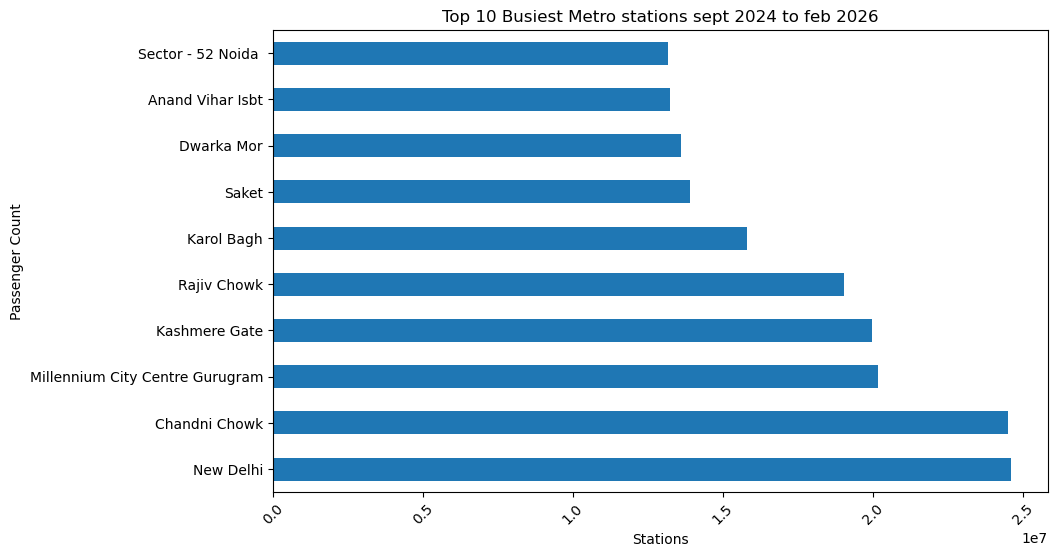

In [16]:
plt.figure(figsize=(10,6))
top10_stations.plot(kind="barh")
plt.title("Top 10 Busiest Metro stations sept 2024 to feb 2026")
plt.xlabel("Stations")
plt.ylabel("Passenger Count")
plt.xticks(rotation=45)

plt.show()

In [18]:
### what are the busiest metro lines in these 5 months?
metro_df.groupby("linename")["count"].sum().sort_values(ascending=False)

linename
LINE02    295077895
LINE03    250549361
LINE06    114033910
LINE01    111685951
LINE07    100136023
LINE08     84336061
LINE04     54830144
LINE05     51269905
RMGL        9719792
LINE09      7202766
Name: count, dtype: int64

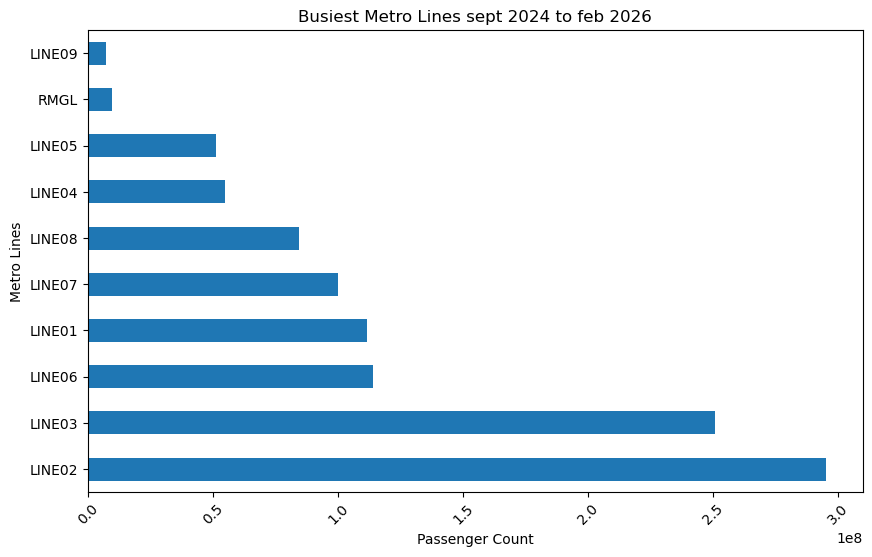

In [23]:
all_lines = metro_df.groupby("linename")["count"].sum().sort_values(ascending=False)
plt.figure(figsize=(10,6))
all_lines.plot(kind="barh")
plt.title("Busiest Metro Lines sept 2024 to feb 2026")
plt.xlabel("Passenger Count")
plt.ylabel("Metro Lines")
plt.xticks(rotation=45)
plt.show()

In [ ]:
### finding lines with most entries and most exits
metro_df["direction"].unique()

<ArrowStringArray>
['Entry', 'Exit']
Length: 2, dtype: str

In [ ]:
# creating dataframe foe entry and exit counts
entry_df = metro_df[metro_df["direction"]=="Entry"]
exit_df= metro_df[metro_df["direction"]=="Exit"]
#creating vars for entry and exit counts by lines
entry_lines=entry_df.groupby("linename")["count"].sum()
exit_lines=exit_df.groupby("linename")["count"].sum()

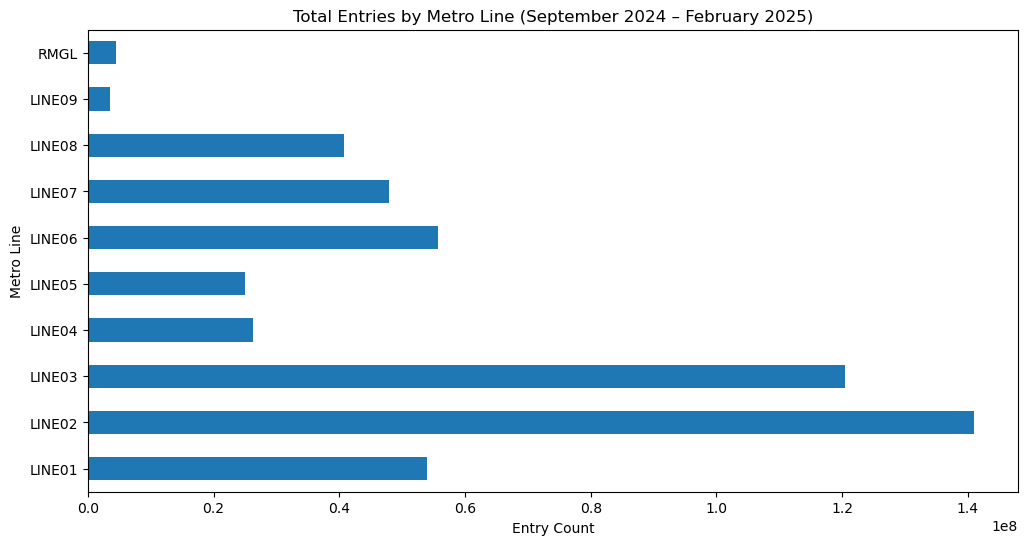

In [30]:
#entry count per line chart
plt.figure(figsize=(12,6))
entry_lines.plot(kind="barh")
plt.title("Total Entries by Metro Line (September 2024 – February 2025)")
plt.xlabel("Entry Count")
plt.ylabel("Metro Line")
plt.show()

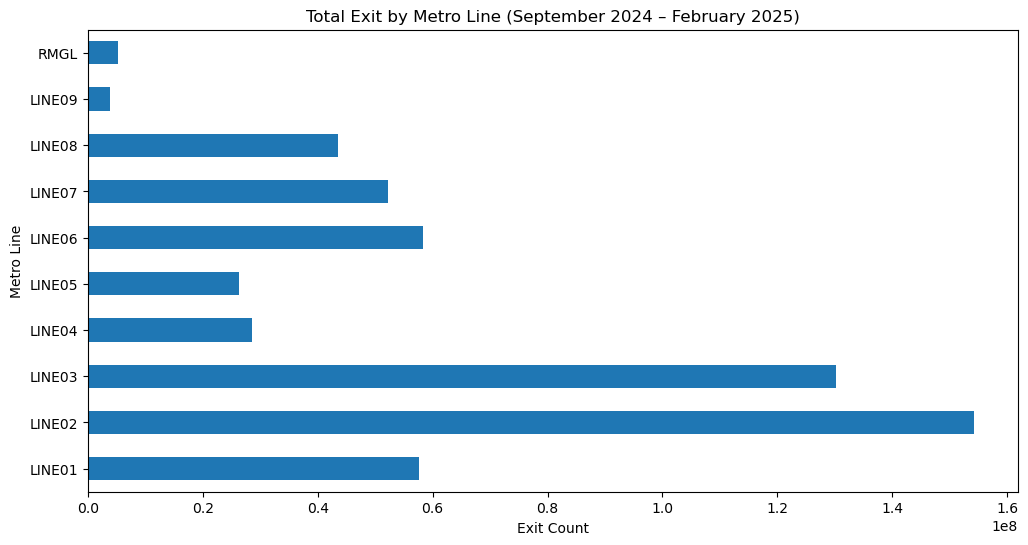

In [31]:
#entry count per line chart
plt.figure(figsize=(12,6))
exit_lines.plot(kind="barh")
plt.title("Total Exit by Metro Line (September 2024 – February 2025)")
plt.xlabel("Exit Count")
plt.ylabel("Metro Line")
plt.show()

In [ ]:
### plotting it sideways to compare entry and exit by lines
line_direction = metro_df.groupby(
    ["linename","direction"])["count"].sum().unstack()
print(line_direction)

direction      Entry       Exit
linename                       
LINE01      54006640   57679311
LINE02     140923579  154154316
LINE03     120426114  130123247
LINE04      26235294   28594850
LINE05      25000517   26269388
LINE06      55674859   58359051
LINE07      47935968   52200055
LINE08      40731982   43604079
LINE09       3441669    3761097
RMGL         4470524    5249268


In [ ]:
plt

FrozenList(['direction'])

<Figure size 1200x600 with 0 Axes>

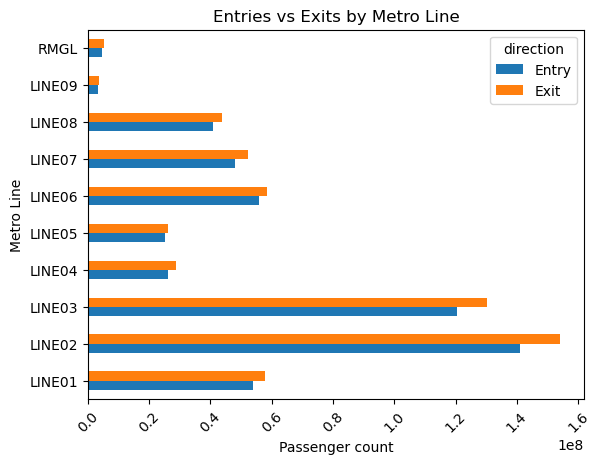

In [39]:
## plotting it
plt.figure(figsize=(12,6))
line_direction.plot(kind="barh")
plt.title("Entries vs Exits by Metro Line")
plt.xlabel("Passenger count")
plt.ylabel("Metro Line")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# understanding total entry vs exit count in delhi metro in these 5 months
metro_df.groupby("direction")["count"].sum()
### WHY IS DATA SHOWING MORE ENTRIES THAN EXITS?
# IS IT BECAUSE OF THE DATA COLLECTION METHOD
# OR IS IT BECAUSE OF THE FACT THAT PEOPLE ARE
# EXITING AT DIFFERENT STATIONS THAN THEY ENTERED?

#DATA NEEDS TO BE CLEANED AND CHECKED FOR ERRORS.

direction
Entry    518847146
Exit     559994662
Name: count, dtype: int64

In [41]:
metro_df.groupby("direction").size()

direction
Entry    936243
Exit     936222
dtype: int64

In [42]:
metro_df.groupby(["month", "direction"]).size().unstack()

direction,Entry,Exit
month,,
December,160188,160167
February,145236,145236
January,160713,160713
November,154980,154980
October,160146,160146
September,154980,154980


In [43]:
metro_df.groupby(["month", "direction"])["count"].sum().unstack()

direction,Entry,Exit
month,,
December,86666260,94219664
February,78002592,86069824
January,88646465,97207591
November,84871850,91205299
October,89894097,95814789
September,90765882,95477495


In [44]:
metro_df.groupby("direction")["count"].describe()

,count,mean,std,min,25%,50%,75%,max
direction,,,,,,,,
Entry,936243.0,554.180000,804.115714,0.0,66.0,287.0,693.0,13486.0
Exit,936222.0,598.143028,892.345157,0.0,74.0,306.0,729.0,15152.0
